<a href="https://colab.research.google.com/github/tinana2k/CS-5567---Deep-Learning/blob/main/HW5_Self-supervised%20Learning/HW5_Tina_Nguyen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Homework 5 - Self-Supervised Learning**

In this homework, we will introduce four different autoencoders for the task of anomaly detection.

# Set up the environment


## Package installation

In [1]:
# Training progress bar
!pip install -q qqdm
!pip install -q tqdm

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


### **Self-code:**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

zip_path = '/content/drive/MyDrive/CS5567/HW5/hw5_data.zip'

print("File exists:", os.path.exists(zip_path))

File exists: True


In [4]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/CS5567/HW5/hw5_data.zip'
extract_path = '/content/'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [5]:
!ls /content/hw5_data

testingset.npy	trainingset.npy


In [6]:
import numpy as np

train_data = np.load('/content/hw5_data/trainingset.npy')
test_data = np.load('/content/hw5_data/testingset.npy')

print("Training data shape:", train_data.shape)
print("Testing data shape:", test_data.shape)

Training data shape: (850, 64, 64, 3)
Testing data shape: (150, 64, 64, 3)


## Untar data

hw5_data contains 2 files
```
hw5_data/
├── trainingset.npy
├── testingset.npy
```

# Import packages

In [7]:
import numpy as np
import random
import torch
import torchvision

from torch.utils.data import DataLoader
from torch.utils.data import (DataLoader, RandomSampler, SequentialSampler,
                              TensorDataset)
import torchvision.transforms as transforms

from torch import nn
import torch.nn.functional as F
from torch.autograd import Variable
import torchvision.models as models

from torch.optim import Adam, AdamW

from sklearn.cluster import MiniBatchKMeans
from scipy.cluster.vq import vq, kmeans

from qqdm import qqdm, format_str
import tqdm
import pandas as pd

import matplotlib.pyplot as plt

import pdb  # use pdb.set_trace() to set breakpoints for debugging




# Loading data

In [8]:

train = np.load('path to/hw5_data/trainingset.npy', allow_pickle=True)
test = np.load('path to/hw5_data/testingset.npy', allow_pickle=True)

print(train.shape)
print(test.shape)

FileNotFoundError: [Errno 2] No such file or directory: 'path to/hw5_data/trainingset.npy'

### **-> Fix the above code:**

In [9]:
import numpy as np

# Loading data
train = np.load('/content/hw5_data/trainingset.npy', allow_pickle=True)
test = np.load('/content/hw5_data/testingset.npy', allow_pickle=True)

print(train.shape)
print(test.shape)

(850, 64, 64, 3)
(150, 64, 64, 3)


## Random seed
Set the random seed to a certain value for reproducibility.

In [10]:
def same_seeds(seed):
    # Python built-in random module
    random.seed(seed)
    # Numpy
    np.random.seed(seed)
    # Torch
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

same_seeds(12345678)

# Autoencoder

# Models & loss (16pts)

In [31]:
class fcn_autoencoder(nn.Module):
    def __init__(self):
        super(fcn_autoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(64*64*3, 128),
            nn.ReLU(True),
            nn.Linear(128, 64),
            nn.ReLU(True),
            nn.Linear(64, 12),
            nn.ReLU(True),
            nn.Linear(12, 3)   ) # (1pt) Todo: Use a linear layer with proper # of input_channels and # of output_channels

        self.decoder = nn.Sequential(
            nn.Linear(3, 12),
            nn.ReLU(True),
            nn.Linear(12, 64),
            nn.ReLU(True),
            nn.Linear(64, 128),
            nn.ReLU(True),
            nn.Linear(128, 64 * 64 * 3),
            nn.Tanh()  ) # (1pt) Todo: Use a Tanh as an activation layer

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


# maybe it can be smaller
class conv_autoencoder(nn.Module):
    def __init__(self):
        super(conv_autoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 12, 4, stride=2, padding=1)    , # (1pt) Todo: Use a conv layer with proper # of input_channels and # of output_channels with kernel_size=4, stride=2 and padding=1
            nn.ReLU()    , # (1pt) Todo: Use a ReLu as an activation layer
            nn.Conv2d(12, 24, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(24, 48, 4, stride=2, padding=1),
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(48, 24, 4, stride=2, padding=1)    , # (1pt) Todo: Use a transpose conv layer with proper # of input_channels and # of output_channels with kernel_size=4, stride=2 and padding=1
            nn.ReLU(),
            nn.ConvTranspose2d(24, 12, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(12, 3, 4, stride=2, padding=1)    , # (1pt) Todo: Use a transpose conv layer with proper # of input_channels and # of output_channels with kernel_size=4, stride=2 and padding=1
            nn.Tanh(),
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


class VAE(nn.Module):
    def __init__(self):
        super(VAE, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 12, 4, stride=2, padding=1)    , # (1pt) Todo: Use a conv layer with proper # of input_channels and # of output_channels with kernel_size=4, stride=2 and padding=1
            nn.ReLU(),
            nn.Conv2d(12, 24, 4, stride=2, padding=1),
            nn.ReLU(),
        )
        self.enc_out_1 = nn.Sequential(
            nn.Conv2d(24, 48, 4, stride=2, padding=1)    , # (1pt) Todo: Use a conv layer with proper # of input_channels and # of output_channels with kernel_size=4, stride=2 and padding=1
            nn.ReLU(),
        )
        self.enc_out_2 = nn.Sequential(
            nn.Conv2d(24, 48, 4, stride=2, padding=1)    , # (1pt) Todo: Use a conv layer with proper # of input_channels and # of output_channels with kernel_size=4, stride=2 and padding=1
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(48, 24, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(24, 12, 4, stride=2, padding=1)    , # (1pt) Todo: Use a transpose conv layer with proper # of input_channels and # of output_channels with kernel_size=4, stride=2 and padding=1
            nn.ReLU(),
            nn.ConvTranspose2d(12, 3, 4, stride=2, padding=1),
            nn.Tanh(),
        )

    def encode(self, x):
        h1 = self.encoder(x)
        return self.enc_out_1(h1), self.enc_out_2(h1)

    def reparametrize(self, mu, logvar):
        std = logvar.mul(0.5).exp_()
        if torch.cuda.is_available():
            eps = torch.cuda.FloatTensor(std.size()).normal_()
        else:
            eps = torch.FloatTensor(std.size()).normal_()
        eps = Variable(eps)
        return eps.mul(std).add_(mu)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparametrize(mu, logvar)
        return self.decode(z), mu, logvar


def loss_vae(recon_x, x, mu, logvar, criterion):
    """
    recon_x: generating images
    x: origin images
    mu: latent mean
    logvar: latent log variance
    """
    mse = criterion(recon_x, x)  # mse loss
    KLD_element = mu.pow(2).add_(logvar.exp()).mul_(-1).add_(1).add_(logvar)
    KLD = torch.sum(KLD_element).mul_(-0.5)
    return mse + KLD


class Resnet(nn.Module):
    def __init__(self, fc_hidden1=1024, fc_hidden2=768, drop_p=0.3, CNN_embed_dim=256):
        super(Resnet, self).__init__()

        self.fc_hidden1, self.fc_hidden2, self.CNN_embed_dim = fc_hidden1, fc_hidden2, CNN_embed_dim

        # CNN architechtures
        self.ch1, self.ch2, self.ch3, self.ch4 = 16, 32, 64, 128
        self.k1, self.k2, self.k3, self.k4 = (5, 5), (3, 3), (3, 3), (3, 3)      # 2d kernal size
        self.s1, self.s2, self.s3, self.s4 = (2, 2), (2, 2), (2, 2), (2, 2)      # 2d strides
        self.pd1, self.pd2, self.pd3, self.pd4 = (0, 0), (0, 0), (0, 0), (0, 0)  # 2d padding

        # encoding components
        resnet = models.resnet18(pretrained=False)
        modules = list(resnet.children())[:-1]      # delete the last fc layer.
        self.resnet = nn.Sequential(*modules)
        self.fc1 = nn.Linear(resnet.fc.in_features, self.fc_hidden1)
        self.bn1 = nn.BatchNorm1d(self.fc_hidden1, momentum=0.01) # (1pt) Todo: Use a batchnorm1d layer with proper input_size and momentum=0.01
        self.fc2 = nn.Linear(self.fc_hidden1, self.fc_hidden2)
        self.bn2 = nn.BatchNorm1d(self.fc_hidden2, momentum=0.01)

        self.fc3_mu = nn.Linear(self.fc_hidden2, self.CNN_embed_dim)      # output = CNN embedding latent variables

        # Sampling vector
        self.fc4 = nn.Linear(self.CNN_embed_dim, self.fc_hidden2)
        self.fc_bn4 = nn.BatchNorm1d(self.fc_hidden2)
        self.fc5 = nn.Linear(self.fc_hidden2, 64 * 4 * 4)
        self.fc_bn5 = nn.BatchNorm1d(64 * 4 * 4) # (1pt) Todo: Use a batchnorm1d layer with proper input_size
        self.relu = nn.ReLU(inplace=True)

        # Decoder
        self.convTrans6 = nn.Sequential(
            nn.ConvTranspose2d(in_channels=64, out_channels=32, kernel_size=self.k4, stride=self.s4,
                               padding=self.pd4),
            nn.BatchNorm2d(32, momentum=0.01),
            nn.ReLU(inplace=True),
        )
        self.convTrans7 = nn.Sequential(
            nn.ConvTranspose2d(in_channels=32, out_channels=8, kernel_size=self.k3, stride=self.s3,
                               padding=self.pd3),
            nn.BatchNorm2d(8, momentum=0.01),
            nn.ReLU(inplace=True),
        )

        self.convTrans8 = nn.Sequential(
            nn.ConvTranspose2d(in_channels=8, out_channels=3, kernel_size=self.k2, stride=self.s2,
                               padding=self.pd2),
            nn.BatchNorm2d(3, momentum=0.01),
            nn.Sigmoid()    # y = (y1, y2, y3) \in [0 ,1]^3
        )


    def encode(self, x):
        x = self.resnet(x)  # ResNet
        x = x.view(x.size(0), -1)  # (1pt)Todo :Flatten output of conv

        # FC layers
        if x.shape[0] > 1:
            x = self.bn1(self.fc1(x))
        else:
            x = self.fc1(x)
        x = self.relu(x)
        if x.shape[0] > 1:
            x = self.bn2(self.fc2(x))
        else:
            x = self.fc2(x)
        x = self.relu(x)
        x = self.fc3_mu(x)
        return x

    def decode(self, z):
        if z.shape[0] > 1:
            x = self.relu(self.fc_bn4(self.fc4(z)))
            x = self.relu(self.fc_bn5(self.fc5(x))).view(-1, 64, 4, 4)
        else:
            x = self.relu(self.fc4(z))
            x = self.relu(self.fc5(x)).view(-1, 64, 4, 4)
        x = self.convTrans6(x)
        x = self.convTrans7(x)
        x = self.convTrans8(x)
        x = nn.functional.interpolate(x, size=(64, 64), mode='bilinear', align_corners=True) # (1pt)Todo : Use a bi-linear interpolation to size of (64,64) with align_corners=True
        return x

    def forward(self, x):
        z = self.encode(x)
        x_reconst = self.decode(z)

        return x_reconst

# Dataset module

Module for obtaining and processing data. The transform function here normalizes image's pixels from [0, 255] to [-1.0, 1.0].


In [32]:
class CustomTensorDataset(TensorDataset):
    """TensorDataset with support of transforms.
    """
    def __init__(self, tensors):
        self.tensors = tensors
        if tensors.shape[-1] == 3:
            # self.tensors = tensors.permute(0, 3, 1, 2)
            self.tensors = tensors.permute(0, 3, 1, 2)

        # You may add some transforms below
        self.transform = transforms.Compose([
                            transforms.Lambda(lambda x: x.to(torch.float32)),
                            transforms.Lambda(lambda x: 2. * x/255. - 1.),
                            # transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
                            ])

    def __getitem__(self, index):
        x = self.tensors[index]

        if self.transform:
            # mapping images to [-1.0, 1.0]
            x = self.transform(x)

        return x

    def __len__(self):
        return len(self.tensors)

# Training

## Initialize
- hyperparameters
- dataloader
- model
- optimizer & loss


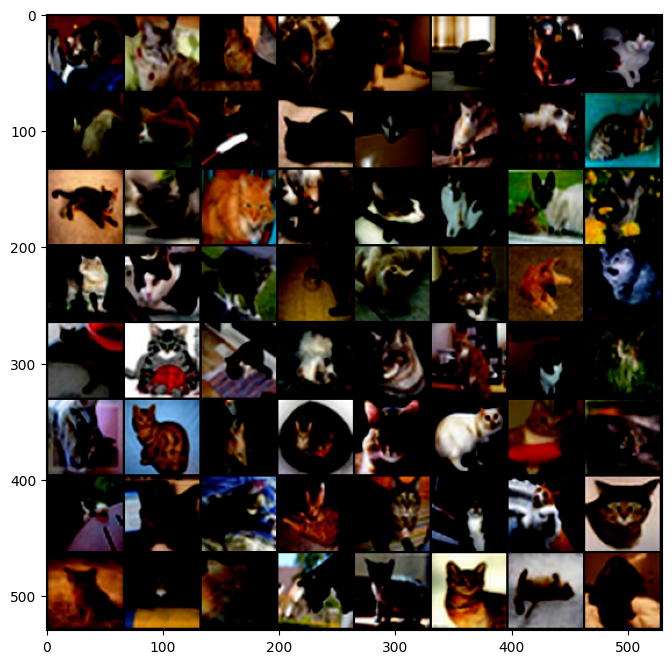

In [33]:
# Training hyperparameters
num_epochs = 20
batch_size = 1024
learning_rate = 1e-6

# Build training dataloader
x = torch.from_numpy(train)
train_dataset = CustomTensorDataset(x)

train_sampler = RandomSampler(train_dataset)
train_dataloader = DataLoader(train_dataset, sampler=train_sampler, batch_size=batch_size)

images = [train_dataset[i] for i in range(64)]
grid_img = torchvision.utils.make_grid(images, nrow=8)
plt.figure(figsize=(8,8))
plt.imshow(grid_img.permute(1, 2, 0))
plt.show()

# Resnet

In [34]:
# Model
model_type = 'resnet'   # selecting a model type from {'cnn', 'fcn', 'vae', 'resnet'}
model_classes = {'resnet': Resnet(), 'fcn':fcn_autoencoder(), 'cnn':conv_autoencoder(), 'vae':VAE(), }
model = model_classes[model_type].cuda()

# Loss and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=learning_rate)

## Training loop

In [35]:
# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Create a new Resnet model
model = Resnet().to(device)

# Check BatchNorm layers
print("bn1:", type(model.bn1))
print("fc_bn5:", type(model.fc_bn5))

# Create optimizer for the new model
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

bn1: <class 'torch.nn.modules.batchnorm.BatchNorm1d'>
fc_bn5: <class 'torch.nn.modules.batchnorm.BatchNorm1d'>


In [36]:
# Set device (GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

best_loss = np.inf
model.train()

qqdm_train = qqdm(range(num_epochs), desc=format_str('bold', 'Training'))

for epoch in qqdm_train:
    tot_loss = list()
    for data in train_dataloader:

        # ===================loading=====================
        if model_type in ['cnn', 'vae', 'resnet']:
            img = data.float().to(device)
        elif model_type in ['fcn']:
            img = data.float().to(device)
            img = img.view(img.shape[0], -1)

        # ===================forward=====================
        output = model(img)
        if model_type in ['vae']:
            loss = loss_vae(output[0], img, output[1], output[2], criterion)
        else:
            loss = criterion(output, img)

        tot_loss.append(loss.item())
        # ===================backward====================
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # ===================save_best====================
    mean_loss = np.mean(tot_loss)
    if mean_loss < best_loss:
        best_loss = mean_loss
        torch.save(model, 'best_model_{}.pt'.format(model_type))

    # ===================log========================
    qqdm_train.set_infos({
      'epoch': f'{epoch + 1:.0f}/{num_epochs:.0f}',
      'loss': f'{mean_loss:.4f}',
    })

    # ===================save_last========================
    torch.save(model, 'last_model_{}.pt'.format(model_type))

 Iters    Elapsed Time      Speed                                               
 0/20           -             -                                                 
Training   0.0% |                                                              | Iters    Elapsed Time      Speed    epoch   loss                               
 1/20   00:00:01<00:00:20  0.91it/s  1/20   0.6207                              
Training   5.0% |███                                                           | Iters    Elapsed Time      Speed    epoch   loss                               
 2/20   00:00:01<00:00:16  1.12it/s  2/20   0.6073                              
Training  10.0% |██████                                                        | Iters    Elapsed Time      Speed    epoch   loss                               
 3/20   00:00:07<00:00:43  0.39it/s  3/20   0.5978                              
Training  15.0% |█████████                                                     | Iters    Elapsed Time      Spee

# FCN_autoencoder

In [37]:
# Model
model_type = 'fcn'   # selecting a model type from {'cnn', 'fcn', 'vae', 'resnet'}
model_classes = {'resnet': Resnet(), 'fcn':fcn_autoencoder(), 'cnn':conv_autoencoder(), 'vae':VAE(), }
model = model_classes[model_type].cuda()

# Loss and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=learning_rate)

## Training loop

In [39]:

# Set device (GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

best_loss = np.inf
model.train()

qqdm_train = qqdm(range(num_epochs), desc=format_str('bold', 'Training'))
for epoch in qqdm_train:
    tot_loss = list()
    for data in train_dataloader:

        # ===================loading=====================
        if isinstance(data, (tuple, list)):
            data = data[0]

        if model_type in ['cnn', 'vae', 'resnet']:
            img = data.float().to(device)
        elif model_type in ['fcn']:
            img = data.float().to(device)
            img = img.view(img.shape[0], -1)

        # ===================forward=====================
        output = model(img)
        if model_type in ['vae']:
            loss = loss_vae(output[0], img, output[1], output[2], criterion)
        else:
            loss = criterion(output, img)

        tot_loss.append(loss.item())
        # ===================backward====================
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # ===================save_best====================
    mean_loss = np.mean(tot_loss)
    if mean_loss < best_loss:
        best_loss = mean_loss
        torch.save(model, 'best_model_{}.pt'.format(model_type))
    # ===================log========================
    qqdm_train.set_infos({
      'epoch': f'{epoch + 1:.0f}/{num_epochs:.0f}',
      'loss': f'{mean_loss:.4f}',
    })
    # ===================save_last========================
    torch.save(model, 'last_model_{}.pt'.format(model_type))


 Iters    Elapsed Time      Speed                                               
 0/20           -             -                                                 
Training   0.0% |                                                              | Iters    Elapsed Time      Speed    epoch   loss                               
 1/20   00:00:00<00:00:04  4.26it/s  1/20   0.2714                              
Training   5.0% |███                                                           | Iters    Elapsed Time      Speed    epoch   loss                               
 3/20   00:00:00<00:00:03  4.85it/s  3/20   0.2714                              
Training  15.0% |█████████                                                     | Iters    Elapsed Time      Speed    epoch   loss                               
 5/20   00:00:01<00:00:03  4.93it/s  5/20   0.2714                              
Training  25.0% |███████████████                                               | Iters    Elapsed Time      Spee

# Conv_Autoencoder

In [40]:
# Model
model_type = 'cnn'   # selecting a model type from {'cnn', 'fcn', 'vae', 'resnet'}
model_classes = {'resnet': Resnet(), 'fcn':fcn_autoencoder(), 'cnn':conv_autoencoder(), 'vae':VAE(), }
model = model_classes[model_type].cuda()

# Loss and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=learning_rate)

## Training loop

In [42]:

import torch
import numpy as np
from qqdm import qqdm

# Set device (GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

best_loss = np.inf
model.train()

qqdm_train = qqdm(range(num_epochs), desc='Training')

for epoch in qqdm_train:
    tot_loss = list()
    for data in train_dataloader:

        # ===================loading=====================
        if isinstance(data, (tuple, list)):
            data = data[0]

        if model_type in ['cnn', 'vae', 'resnet']:
            img = data.float().to(device)
        elif model_type in ['fcn']:
            img = data.float().to(device)
            img = img.view(img.shape[0], -1)

        # ===================forward=====================
        output = model(img)
        if model_type in ['vae']:
            loss = loss_vae(output[0], img, output[1], output[2], criterion)
        else:
            loss = criterion(output, img)

        tot_loss.append(loss.item())

        # ===================backward====================
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # ===================save_best====================
    mean_loss = np.mean(tot_loss)
    if mean_loss < best_loss:
        best_loss = mean_loss
        torch.save(model, 'best_model_{}.pt'.format(model_type))

    # ===================log========================
    qqdm_train.set_infos({
        'epoch': f'{epoch + 1:.0f}/{num_epochs:.0f}',
        'loss': f'{mean_loss:.4f}',
    })

    # ===================save_last========================
    torch.save(model, 'last_model_{}.pt'.format(model_type))


 Iters    Elapsed Time      Speed                                               
 0/20           -             -                                                 
Training   0.0% |                                                              | Iters    Elapsed Time      Speed    epoch   loss                               
 1/20   00:00:00<00:00:03  4.96it/s  1/20   0.2920                              
Training   5.0% |███                                                           | Iters    Elapsed Time      Speed    epoch   loss                               
 3/20   00:00:00<00:00:02  6.18it/s  3/20   0.2920                              
Training  15.0% |█████████                                                     | Iters    Elapsed Time      Speed    epoch   loss                               
 5/20   00:00:00<00:00:02  6.82it/s  5/20   0.2920                              
Training  25.0% |███████████████                                               | Iters    Elapsed Time      Spee

# VAE

In [43]:
# Model
model_type = 'vae'   # selecting a model type from {'cnn', 'fcn', 'vae', 'resnet'}
model_classes = {'resnet': Resnet(), 'fcn':fcn_autoencoder(), 'cnn':conv_autoencoder(), 'vae':VAE(), }
model = model_classes[model_type].cuda()

# Loss and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=learning_rate)

## Training loop

In [45]:

best_loss = np.inf
model.train()

qqdm_train = qqdm(range(num_epochs), desc='Training')
for epoch in qqdm_train:
    tot_loss = list()
    for data in train_dataloader:

        # ===================loading=====================
        if model_type in ['cnn', 'vae', 'resnet']:
            img = data.float().cuda()
        elif model_type in ['fcn']:
            img = data.float().cuda()
            img = img.view(img.shape[0], -1)

        # ===================forward=====================
        output = model(img)
        if model_type in ['vae']:
            loss = loss_vae(output[0], img, output[1], output[2], criterion)
        else:
            loss = criterion(output, img)

        tot_loss.append(loss.item())
        # ===================backward====================
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # ===================save_best====================
    mean_loss = np.mean(tot_loss)
    if mean_loss < best_loss:
        best_loss = mean_loss
        torch.save(model, 'best_model_{}.pt'.format(model_type))
    # ===================log========================
    qqdm_train.set_infos({
      'epoch': f'{epoch + 1:.0f}/{num_epochs:.0f}',
      'loss': f'{mean_loss:.4f}',
    })
    # ===================save_last========================
    torch.save(model, 'last_model_{}.pt'.format(model_type))



 Iters    Elapsed Time      Speed                                               
 0/20           -             -                                                 
Training   0.0% |                                                              |/tmp/ipykernel_730/3739607233.py:89: UserWarning: The torch.cuda.*DtypeTensor constructors are no longer recommended. It's best to use methods such as torch.tensor(data, dtype=*, device='cuda') to create tensors. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/tensor/python_tensor.cpp:78.)
  eps = torch.cuda.FloatTensor(std.size()).normal_()
 Iters    Elapsed Time      Speed    epoch    loss                              
 1/20   00:00:00<00:00:03  4.76it/s  1/20   2619.8540                           
Training   5.0% |███                                                           | Iters    Elapsed Time      Speed    epoch    loss                              
 3/20   00:00:00<00:00:03  5.12it/s  3/20   2614.5906                           
T